# 模块 5 视觉跟踪（`/visual_tracker`）—— 纯逻辑用法与效果展示

对应 `design/函数接口.md` 模块 5（`track`）、`design/数据类型.md` 1.3（`VisualTrack`）。

**职责**：订阅 `/detections`，BoT-SORT 跟踪并赋予目标唯一 ID，输出 `/visual/tracks`。

**算法**：卡尔曼滤波（匀速模型）+ **两阶段关联**（高分→全部航迹；低分→未匹配航迹）
+ 贪心 IoU 匹配。ReID 关闭、GMC 为可插拔钩子（决策文档第九章第 3 条：
单目标场景纯 SORT 即可）。

> ### 与文档的一致性
> - 签名 `track(detections) -> list[VisualTrack]` **原样保留**；
> - 跨帧状态住在 `BotSortTracker` **实例**里，由节点成员变量持有（移植文档 8.1）；
> - `area_ratio` 需画面尺寸，而签名无图像入参 → 由 `set_frame_size()` 注入。

## 0. 环境准备

In [1]:
# 环境准备：把 code/ 加入 import 路径（notebook 位于 ai4/code/，直接同目录）
import os, sys
CODE_DIR = os.getcwd()
if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)
print("CODE_DIR =", CODE_DIR)

# 运行阶段开关（代码书写原则第 1 条）：dev 抛错 / onboard 兜底
# os.environ["UAV_STAGE"] = "onboard"
from config import STAGE, ONBOARD
print("STAGE =", STAGE, " ONBOARD =", ONBOARD)

CODE_DIR = /home/demo/桌面/ai4/code
STAGE = dev  ONBOARD = False


In [2]:
# ---- ① 依赖注入：numpy 必须取自隔离目录 m4_deps（ultralytics 要求 >=1.18.5，系统只有 1.17.4）----
import os as _os, sys as _sys, glob as _glob
_HERE = _os.path.abspath(_os.getcwd())
ROOT = _HERE if _os.path.isdir(_os.path.join(_HERE, "catkin_ws")) else _os.path.dirname(_HERE)

DEPS = _os.path.join(ROOT, "catkin_ws", "src", "uav_tracking", "lib", "m4_deps")
if _os.path.isdir(DEPS):
    _sys.path.insert(0, DEPS)

import numpy as _np
print("ROOT     =", ROOT)
print("m4_deps  =", DEPS, "(存在)" if _os.path.isdir(DEPS) else "(不存在，视觉推理将跳过)")
print("numpy    =", _np.__version__, "(1.21.x = 隔离生效 / 1.17.4 = 隔离失效)")

# 取到 numpy 后，把 m4_deps 挪到 sys.path 末尾：torch/ultralytics 仍能导入，
# 但不会再遮住系统的 matplotlib —— m4_deps 里的 matplotlib 是 pip --target 装残的
# （import matplotlib.pyplot 会报 cannot import name 'rcParams'），实测不可用。
if DEPS in _sys.path:
    _sys.path.remove(DEPS)
    _sys.path.append(DEPS)

# ---- ② 绘图环境（代码书写原则 §4/§5：统一 %matplotlib inline + 中文字体）----
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["Noto Sans CJK JP", "WenQuanYi Zen Hei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("matplotlib =", matplotlib.__version__, "(系统)")


def _find_real_image():
    for pat in ("test/M4_*/*/assets/*.jpg", "test/M4_*/*/assets/*.png",
                "test/M4_*/证据/*.png", "data/**/*.jpg", "assets/*.jpg"):
        hits = sorted(h for h in _glob.glob(_os.path.join(ROOT, pat), recursive=True)
                      if "ipynb_checkpoints" not in h)
        if hits:
            return hits[0]
    return ""


REAL_IMAGE = _find_real_image()
# 权重默认是相对路径 "yolov8n.pt"，notebook 工作目录是 code/，必须显式指向仓库根
MODEL_PATH = (_os.path.join(ROOT, "yolov8n.pt")
              if _os.path.isfile(_os.path.join(ROOT, "yolov8n.pt")) else "yolov8n.pt")
print("真实素材  =", REAL_IMAGE or "(未找到，退化为合成图)")
print("模型权重  =", MODEL_PATH)
%matplotlib inline


ROOT     = /home/demo/桌面/ai4
m4_deps  = /home/demo/桌面/ai4/catkin_ws/src/uav_tracking/lib/m4_deps (存在)
numpy    = 1.21.6 (1.21.x = 隔离生效 / 1.17.4 = 隔离失效)


matplotlib = 3.1.2 (系统)
真实素材  = /home/demo/桌面/ai4/test/M4_现场验证/实时演示/assets/bus.jpg
模型权重  = /home/demo/桌面/ai4/yolov8n.pt


## 1. 构造跟踪器

`BotSortTracker` 是**有状态**的（这正是"跨帧状态放节点"的载体），
每次新建实例即一条独立的跟踪会话。

In [3]:
from visual_tracker import BotSortTracker
from datatypes import DetectedTarget

def det(x, y, w=60.0, h=60.0, conf=0.9, cls=0):
    "按文档 bbox=(x, y, w, h) 构造检测。"
    return DetectedTarget(class_id=cls, confidence=conf, bbox=(x, y, w, h))

t = BotSortTracker(
    track_high_thresh=0.5, track_low_thresh=0.1, new_track_thresh=0.6,
    track_buffer=30, match_thresh=0.8, frame_size=(640, 480),
)
print("track_high_thresh =", t.track_high_thresh)
print("track_low_thresh  =", t.track_low_thresh)
print("new_track_thresh  =", t.new_track_thresh)
print("track_buffer      =", t.track_buffer, "（帧）")
print("match_thresh      =", t.match_thresh)
print("frame_size        =", t.frame_size, "（area_ratio 的计算依据）")

track_high_thresh = 0.5
track_low_thresh  = 0.1
new_track_thresh  = 0.6
track_buffer      = 30 （帧）
match_thresh      = 0.8
frame_size        = (640, 480) （area_ratio 的计算依据）


## 2. 单帧跟踪

`track()` 返回**本帧更新到**的航迹；丢失中的航迹（仍在 buffer 内）**不输出**，
避免下游 `/pid_controller` 去追"幽灵目标"。

In [4]:
out = t.track([det(280.0, 200.0, w=120.0, h=90.0, conf=0.92)])
for it in out:
    print("id=%d  bbox=(%.0f, %.0f, %.0f, %.0f)  area_ratio=%.4f"
          % (it.id, it.bbox[0], it.bbox[1], it.bbox[2], it.bbox[3], it.area_ratio))

id=1  bbox=(280, 200, 120, 90)  area_ratio=0.0352


## 3. ID 跨帧稳定性（跟踪的核心意义）

目标连续移动时，ID 必须保持不变——否则下游无法判断"这是不是同一个目标"。

In [5]:
t = BotSortTracker(frame_size=(640, 480))
ids, centers, areas = [], [], []
for i in range(8):
    x, y = 100.0 + i * 12.0, 200.0 + i * 8.0
    res = t.track([det(x, y, w=60.0 + i * 10.0, h=45.0 + i * 7.5)])   # 目标变大 = 逼近
    if res:
        ids.append(res[0].id); centers.append((x + 30.0, y + 30.0)); areas.append(res[0].area_ratio)
    print("第 %d 帧  bbox=(%6.1f,%6.1f)  ->  %s"
          % (i + 1, x, y, ("id=%d" % res[0].id) if res else "无"))

print()
print("ID 序列:", ids)
print("是否全程同一 ID:", len(set(ids)) == 1)

第 1 帧  bbox=( 100.0, 200.0)  ->  id=1
第 2 帧  bbox=( 112.0, 208.0)  ->  id=1
第 3 帧  bbox=( 124.0, 216.0)  ->  id=1
第 4 帧  bbox=( 136.0, 224.0)  ->  id=1
第 5 帧  bbox=( 148.0, 232.0)  ->  id=1
第 6 帧  bbox=( 160.0, 240.0)  ->  id=1
第 7 帧  bbox=( 172.0, 248.0)  ->  id=1
第 8 帧  bbox=( 184.0, 256.0)  ->  id=1

ID 序列: [1, 1, 1, 1, 1, 1, 1, 1]
是否全程同一 ID: True


## 4. 丢失—恢复保 ID

目标短暂丢失（漏检/遮挡）后重新出现，只要在 `track_buffer` 帧内恢复，
**ID 保持不变**；超过 buffer 则淘汰，新目标拿新 ID。

In [6]:
def id_after_loss(gap_frames, buffer=30):
    tt = BotSortTracker(frame_size=(640, 480), track_buffer=buffer)
    first = tt.track([det(100.0, 100.0)])
    for _ in range(gap_frames):
        tt.track([])                       # 连续空帧
    later = tt.track([det(104.0, 102.0)])
    same = bool(first and later and first[0].id == later[0].id)
    return (first[0].id if first else None), (later[0].id if later else None), same

print("%-12s %-10s %-10s %s" % ("丢失帧数", "原 ID", "恢复后 ID", "是否同一 ID"))
for gap in (1, 5, 20, 31, 40):
    a, b, same = id_after_loss(gap)
    print("%-12d %-10s %-10s %s" % (gap, a, b, same))
print()
print("结论：丢失帧数 <= track_buffer(30) 时 ID 保持；超出则淘汰重建。")

丢失帧数         原 ID       恢复后 ID     是否同一 ID
1            1          1          True
5            1          1          True
20           1          1          True
31           1          2          False
40           1          2          False

结论：丢失帧数 <= track_buffer(30) 时 ID 保持；超出则淘汰重建。


## 5. 两阶段关联（BoT-SORT 的关键特性）

目标被遮挡时检测置信度会掉下去。BoT-SORT 用**低分检测与未匹配航迹再匹配一次**
（阶段二）来保住 ID，而不是当成新目标。这是它相对原版 SORT 的主要收益。

In [7]:
t = BotSortTracker(track_high_thresh=0.5, track_low_thresh=0.1, frame_size=(640, 480))
high = t.track([det(100.0, 100.0, conf=0.90)])
low = t.track([det(102.0, 101.0, conf=0.30)])     # 分数掉到高分阈值以下
print("高分帧 id =", high[0].id if high else None)
print("低分帧 id =", low[0].id if low else None, "  conf=0.30 仍被关联到同一航迹")

t2 = BotSortTracker(track_high_thresh=0.5, track_low_thresh=0.4,
                    new_track_thresh=0.6, frame_size=(640, 480))
t2.track([det(100.0, 100.0, conf=0.9)])
below = t2.track([det(102.0, 101.0, conf=0.2)])   # 低于低分阈值 -> 完全忽略
print("低于低分阈值(0.4) 的检测 -> 输出", below, "（既不关联也不新建）")

高分帧 id = 1
低分帧 id = 1   conf=0.30 仍被关联到同一航迹
低于低分阈值(0.4) 的检测 -> 输出 [] （既不关联也不新建）


## 6. `area_ratio` 与画面尺寸

`area_ratio = bbox 面积 / 画面总面积`，是 `/state_machine` 判定"逼近至百米"的
2% 判据的直接来源。画面尺寸由节点注入（`track()` 签名无图像入参）。

In [8]:
rows = []
for w, h in ((64, 48), (120, 90), (200, 150)):
    for size in ((640, 480), (320, 240)):
        tt = BotSortTracker(frame_size=size)
        r = tt.track([det(0.0, 0.0, w=float(w), h=float(h))])[0]
        rows.append((w, h, "%dx%d" % size, (w * h) / float(size[0] * size[1]), r.area_ratio))

print("%-10s %-10s %-12s %-14s" % ("bbox w×h", "画面", "期望 area_ratio", "实际 area_ratio"))
for w, h, size, expect, got in rows:
    print("%-10s %-10s %-14.5f %-14.5f %s" % ("%d×%d" % (w, h), size, expect, got,
                                              "OK" if abs(expect - got) < 1e-9 else "MISMATCH"))

bbox w×h   画面         期望 area_ratio 实际 area_ratio 
64×48      640x480    0.01000        0.01000        OK
64×48      320x240    0.04000        0.04000        OK
120×90     640x480    0.03516        0.03516        OK
120×90     320x240    0.14062        0.14062        OK
200×150    640x480    0.09766        0.09766        OK
200×150    320x240    0.39062        0.39062        OK


## 7. 可视化（坐标与配色统一）

代码书写原则第 5 条：**画图时坐标统一、配色统一**。
下图统一使用 `双轴含义 fixed`、同一套颜色（与 `detector.ipynb` 一致），
对比"目标移动"与"ID 保持不变"。

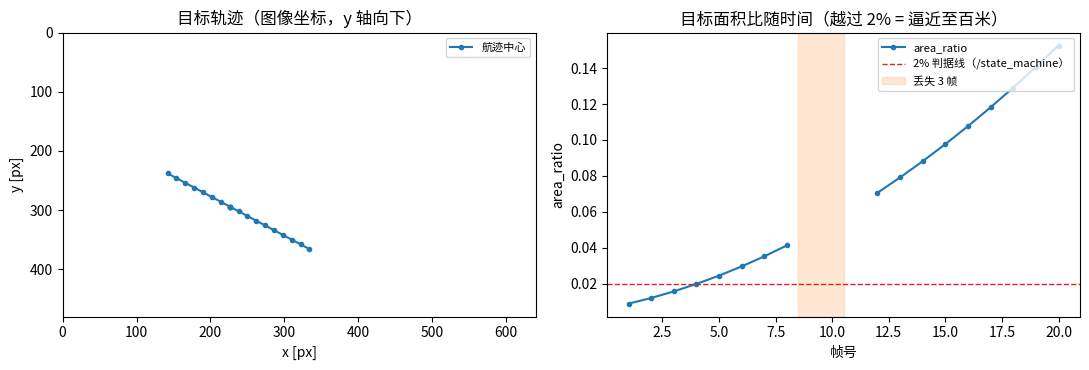

有效帧 ID 集合: [1]  -> ID 全程稳定


In [9]:
import matplotlib.pyplot as plt

# ---- 全项目统一配色 / 坐标约定（代码书写原则第 5 条）----
COLOR_TRACK = "#1f77b4"     # 航迹
COLOR_REF = "#d62728"       # 参考线
COLOR_LOSS = "#ff7f0e"      # 丢失区间

t = BotSortTracker(frame_size=(640, 480), track_buffer=30)
seq_frames, seq_x, seq_y, seq_id, seq_area = [], [], [], [], []
x, y = 100.0, 200.0
for i in range(20):
    if i in (8, 9, 10):                     # 模拟丢失 3 帧
        res = t.track([])
    else:
        x, y = x + 12.0, y + 8.0
        res = t.track([det(x, y, w=60.0 + i * 10.0, h=45.0 + i * 7.5)])   # 目标变大 = 逼近
    seq_frames.append(i + 1)
    seq_x.append(x + 30.0); seq_y.append(y + 30.0)
    seq_id.append(res[0].id if res else None)
    seq_area.append(res[0].area_ratio if res else None)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

# 左：图像坐标（y 轴向下，与图像坐标系一致）
axes[0].plot(seq_x, seq_y, "-o", color=COLOR_TRACK, markersize=3, label="航迹中心")
axes[0].axvspan(0, 640, alpha=0, color="none")
axes[0].set_xlim(0, 640); axes[0].set_ylim(480, 0)          # y 反向 = 图像坐标
axes[0].set_xlabel("x [px]"); axes[0].set_ylabel("y [px]")
axes[0].set_title("目标轨迹（图像坐标，y 轴向下）")
axes[0].legend(loc="best", fontsize=8)

# 右：area_ratio 随时间（丢失区间标出）
axes[1].plot(seq_frames, seq_area, "-o", color=COLOR_TRACK, markersize=3, label="area_ratio")
axes[1].axhline(0.02, color=COLOR_REF, linestyle="--", linewidth=1,
                label="2% 判据线（/state_machine）")
axes[1].axvspan(8.5, 10.5, color=COLOR_LOSS, alpha=0.18, label="丢失 3 帧")
axes[1].set_xlabel("帧号"); axes[1].set_ylabel("area_ratio")
axes[1].set_title("目标面积比随时间（越过 2% = 逼近至百米）")
axes[1].legend(loc="upper right", fontsize=8)

plt.tight_layout(); plt.show()

ids = [i for i in seq_id if i is not None]
print("有效帧 ID 集合:", sorted(set(ids)), " ->", "ID 全程稳定" if len(set(ids)) == 1 else "ID 发生变化")

## 8. 小结

| 约定 | 取值 | 出处 |
|---|---|---|
| 算法 | 卡尔曼 + 两阶段 IoU 关联（BoT-SORT 核心） | 第九章第 3 条 |
| 输出 | `VisualTrack(id, bbox=(x,y,w,h), area_ratio)` | 数据类型.md 1.3 |
| 无输入/无航迹 | 返回 `[]`，节点发空 `VisualTrackArray` | 设计原则第 5 条 |
| 丢失中的航迹 | **不输出**（避免追幽灵目标） | 设计 3.3 / 3.6 |
| 跨帧状态 | `BotSortTracker` 实例，节点持有 | 移植文档 8.1 |
| `area_ratio` | 由 `set_frame_size()` 注入画面尺寸 | `track()` 签名无图像入参 |